# NGC 4689 and NGC 4351 | SFH weights and stellar M/L on Setonix

The 19 November rSFMS comparison reported median **7000 SFH16 minus 8900** stellar surface-density shifts of **+0.205 dex for NGC 4689** and **−0.159 dex for NGC 4351** on the paired SF sample. Here we compare saved stellar fits only on common continuum spaxels with finite `SNR_POSTFIT > 25` in both runs. The selections differ, so compare the signs and spatial patterns before comparing the medians.

We ask where the fits redistribute R-band light across age and [M/H], how much that changes intrinsic $M/L_R$, and whether stellar reddening reinforces or offsets it. At fixed pre-internal-dust R-band light the predicted mass shift is $Deltalog_{10}(M/L_R)+0.4k_RDelta E(B-V)_\star$. Stellar reddening enters the luminosity correction directly and can covary with fitted SFH weights. The calculation reads saved FITS and prepares SSP normalizations. It needs no data cubes, R-band flux maps, or pPXF refits.

The two runs also differ in their fit configuration and binning. This comparison diagnoses the saved solutions. A controlled wavelength experiment would hold the binning and fit settings fixed.

In [1]:
from pathlib import Path
import os

for key in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS"):
    os.environ[key] = "1"

PRODUCTS = Path("/scratch/pawsey1308/mauve/products")
HOME = Path("/home/rhuang")
TUTORIAL = Path("/software/projects/pawsey1308/ngist_supplementary_public/ngistTutorial")
GALAXIES = ("NGC4689", "NGC4351")
RUNS = ("8900", "7000 SFH16")
ROOTS = dict(zip(RUNS, ("v3tk_v7.6.8", "v3tk_v7.6.8_7000")))
SNR_MIN = 25
BIN_JACCARD_MIN = 0.5
REGIONS = {}  # Optional named rectangles: {"NGC4689": {"region": (xmin, xmax, ymin, ymax)}}

## Read the saved fits and reconstruct M/L

Use the prepared-template normalization from the existing Setonix `Mass.py` and the same BaSTI+Chabrier photometry table. For SSP $j$, the fitted coefficient $w_j$ multiplies a template divided by its prepared mean $n_j$. The inferred R-band light fraction is proportional to $w_j\ell_{R,j}/n_j$, using the tabulated SSP R luminosity $\ell_{R,j}$. Intrinsic $M/L_R$ is the R-light-weighted mean of the SSP $M/L_R$ values. The luminosity proxy's common zero point cancels.

The nGIST spatial table gives the fit bin at each image pixel. Compare its reconstructed BINID with the native map where available, and align runs through the celestial WCS. Bin IDs are local to each run.

In [2]:
import ast
import hashlib
import re
import numpy as np
import scipy
import astropy
import yaml
import pandas as pd
import matplotlib.pyplot as plt
import ppxf as ppxf_package
from ppxf.ppxf_util import gaussian_filter1d, log_rebin
from scipy.interpolate import interp1d
from astropy.io import fits
from astropy.wcs import WCS
from IPython.display import display

# Mass.py is also a CLI. Load only the tested numerical helpers, as in
# 20261031_SETONIX_MAUVE_ML_Three_Methods.ipynb.
mass_file = HOME / "Mass.py"
table_file = HOME / "BaSTI+Chabrier.dat"
helpers = {
    "sha256_file", "parse_template_filename_key", "_resource_path", "load_run_setup",
    "load_lsf", "build_template_norm_flux_lookup", "r_light_mass_to_light", "calzetti_k",
}
constants = {"NGIST_REVISION", "TEMPLATE_VELSCALE_RATIO", "_TEMPLATE_RE"}
tree = ast.parse(mass_file.read_text())
nodes = [node for node in tree.body if
         (isinstance(node, ast.FunctionDef) and node.name in helpers) or
         (isinstance(node, ast.Assign) and
          any(isinstance(t, ast.Name) and t.id in constants for t in node.targets))]
mass = dict(globals(), __file__=str(mass_file))
exec(compile(ast.Module(body=nodes, type_ignores=[]), str(mass_file), "exec"), mass)
if missing := helpers - mass.keys():
    raise RuntimeError(f"{mass_file} is missing helpers: {sorted(missing)}")

table_names = ("IMF slope MH Age U B V R I J H K UminusV BminusV VminusR VminusI "
               "VminusJ VminusH VminusK ML_U ML_B ML_V ML_R ML_I ML_J ML_H ML_K "
               "F439W F555W F675W F814W C439_555 C555_675 C555_814").split()
table = np.genfromtxt(table_file, names=table_names, skip_header=2, dtype=None, encoding=None)
phot = {(round(float(r["Age"]), 2), round(float(r["MH"]), 2)):
        (10 ** (-0.4 * float(r["R"])), float(r["ML_R"]))
        for r in table if r["IMF"] == "Ch"}
dust_factor = 0.4 * float(mass["calzetti_k"](0.64))  # Mass.py Bessell R, dex per mag E(B-V).
print(f"0.4 k_R = {dust_factor:.4f} dex per mag of stellar E(B-V)")
print("Mass.py SHA256", mass["sha256_file"](mass_file))
print("Photometry table SHA256", mass["sha256_file"](table_file))

0.4 k_R = 1.3732 dex per mag of stellar E(B-V)
Mass.py SHA256 658c1e0b55dc0b5f4d491d9089987484bd33a2072055add15f9408d4aa081873
Photometry table SHA256 feb424f764dfd6e9344ca993e86b246f8c756438a978bd2e533bebce5fc07443


In [3]:
def product(folder, stem, required=True):
    for ending in (".fits", ".fits.gz"):
        path = folder / (stem + ending)
        if path.is_file():
            return path
    if required:
        raise FileNotFoundError(f"{folder / stem}.fits[.gz]")


def check_grid(reference, candidate, shape, label):
    a, b = WCS(reference).celestial, WCS(candidate).celestial
    if not (a.has_celestial and b.has_celestial):
        raise ValueError(f"{label}: missing celestial WCS")
    ny, nx = shape
    x = np.array([0, nx - 1, 0, nx - 1, (nx - 1) / 2])
    y = np.array([0, 0, ny - 1, ny - 1, (ny - 1) / 2])
    error = a.pixel_to_world(x, y).separation(b.pixel_to_world(x, y)).arcsec
    if not np.isfinite(error).all() or error.max() > 0.01:
        raise ValueError(f"{label}: WCS mismatch (tolerance 0.01 arcsec)")
    return float(error.max())


def table_bin_image(path, shape, reference):
    with fits.open(path, memmap=False) as h:
        pixsize = h[0].header["PIXSIZE"]
        t = h["TABLE"].data
        x, y = -t["X"], t["Y"]
        # Same coordinates and reversal as nGIST writeFITS/save_maps_fits.py.
        col = np.rint((x - x.min()) / pixsize).astype(int)[::-1]
        row = np.rint((y - y.min()) / pixsize).astype(int)
        if (row.max() + 1, col.max() + 1) != shape:
            raise ValueError(f"{path}: table and SFH image shapes differ")
        flat = np.ravel_multi_index((row, col), shape)
        if np.unique(flat).size != np.prod(shape) or len(t) != np.prod(shape):
            raise ValueError(f"{path}: expected one table row for each image pixel")
        check_grid(reference, h[2].header, shape, str(path))
        image = np.full(shape, -1, dtype=np.int32)
        good = t["BIN_ID"] >= 0
        image[row[good], col[good]] = t["BIN_ID"][good]
    return image


def map_values(binid, values):
    image = np.full(binid.shape, np.nan)
    good = binid >= 0
    image[good] = values[binid[good]]
    return image


def load_case(galaxy, run):
    prefix = galaxy if run == "8900" else galaxy + "_SFH16"
    folder = PRODUCTS / ROOTS[run] / prefix
    with fits.open(product(folder, prefix + "_sfh_maps"), memmap=False) as h:
        header = h["AGE"].header.copy()
        sfh = {key: h[key].data.astype(float) for key in ("AGE", "METAL", "EBV", "SNR_POSTFIT")}
        shape = h["AGE"].data.shape
        for key, array in sfh.items():
            if array.shape != shape:
                raise ValueError(f"{prefix} {key}: shape mismatch")
            check_grid(header, h[key].header, shape, f"{prefix} {key}")
    binid = table_bin_image(product(folder, prefix + "_table"), shape, header)
    native_map = product(folder, prefix + "_spatial_binning_maps", required=False)
    if native_map:
        with fits.open(native_map, memmap=False) as h:
            native = h["BINID"].data
            check_grid(header, h["BINID"].header, shape, str(native_map))
            np.testing.assert_array_equal(binid, np.where(np.isfinite(native) & (native >= 0), native, -1))
    wp = product(folder, prefix + "_sfh_weights")
    with fits.open(wp, memmap=False) as h:
        weights = h["WEIGHTS"].data["WEIGHTS"].astype(float)
        wh = h["WEIGHTS"].header.copy()
        grid = h["GRID"].data
        log_age = grid["LOGAGE"].astype(float)
        mh = grid["METAL"].astype(float)
        alpha = grid["ALPHA"].astype(float)
        keys = [(round(10**a, 2), round(z, 2), round(e, 2)) for a, z, e in zip(log_age, mh, alpha)]
    if not np.array_equal(np.unique(binid[binid >= 0]), np.arange(len(weights))):
        raise ValueError(f"{prefix}: nonnegative BIN_IDs must span the SFH weight rows")
    setup = mass["load_run_setup"](wp, wh, HOME, lsf_dir=TUTORIAL / "configFiles")
    config = setup["config"]
    fit = config["SFH"]
    if wh["MDEG"] != fit["MDEG"]:
        raise ValueError(f"{prefix}: MDEG differs in CONFIG and the weights header")
    setup_lsf = mass["load_lsf"](setup["data_lsf_path"], setup["template_lsf_path"], setup["redshift"])
    norm, prep = mass["build_template_norm_flux_lookup"](
        TUTORIAL / "spectralTemplates" / fit["LIBRARY"], setup["lmin"], setup["lmax"],
        lsf_data=setup_lsf[0], lsf_templates=setup_lsf[1],
        template_velscale=setup["template_velscale"], grid_keys=keys)
    lum, ssp_ml = np.array([phot[key[:2]] for key in keys]).T
    norm = np.array([norm[key] for key in keys])
    ml, rfrac = mass["r_light_mass_to_light"](weights, ssp_ml, lum, norm)
    info = dict(galaxy=galaxy, run=run, LMIN=fit["LMIN"], LMAX=fit["LMAX"], MDEG=fit["MDEG"],
                spec_mask=fit["SPEC_MASK"], library=fit["LIBRARY"], bins=len(weights), SSPs=len(keys),
                foreground_EBV=config["READ_DATA"]["EBmV"], VELSCALE=setup["galaxy_velscale"],
                weights_path=str(wp), config_sha256=setup["config_sha256"],
                template_sha256=prep["template_manifest_sha256"],
                bin_map="table vs native verified" if native_map else "table + SFH WCS")
    return dict(info=info, keys=keys, log_age=log_age, weights=weights, rfrac=rfrac, logml=np.log10(ml),
                lum=lum, ssp_ml=ssp_ml, norm=norm, binid=binid, header=header, **sfh)


cases = {}
for galaxy in GALAXIES:
    for run in RUNS:
        print(f"Loading {galaxy} | {run}", flush=True)
        cases[galaxy, run] = load_case(galaxy, run)
inventory = pd.DataFrame([c["info"] for c in cases.values()])
display(inventory.drop(columns=["weights_path", "config_sha256", "template_sha256"]))

Loading NGC4689 | 8900


Loading NGC4689 | 7000 SFH16


Loading NGC4351 | 8900


Loading NGC4351 | 7000 SFH16


,galaxy,run,LMIN,LMAX,MDEG,spec_mask,library,bins,SSPs,foreground_EBV,VELSCALE,bin_map
0,NGC4689,8900,4800,8900,23,specMask_KIN_narrow10,EMILES_baseFe_safe/,10347,477,0.0196,41.0,table vs native verified
1,NGC4689,7000 SFH16,4800,7000,16,specMask_KIN_narrow10,EMILES_baseFe_safe/,10227,477,0.0196,41.0,table vs native verified
2,NGC4351,8900,4800,8900,23,specMask_KIN_narrow10,EMILES_baseFe_safe/,2170,477,0.0248,41.0,table vs native verified
3,NGC4351,7000 SFH16,4800,7000,16,specMask_KIN_narrow10,EMILES_baseFe_safe/,2347,477,0.0248,41.0,table + SFH WCS


## Paired mass terms and the age–metallicity distribution

Use each run's own Voronoi membership on the shared native grid, with $\mathrm{S/N}_{\rm postfit}>25$ by default in both fits. The S/N cut is applied before the paired decomposition, distributions, plots and example selection. Bin-pair overlap is intersection over union (Jaccard) of the original apertures, so it describes the full spatial support of each bin contributing to a selected pixel. High-overlap summaries test sensitivity to the changed binning. Their sample can cover different parts of the galaxy. Percentiles describe spatial distributions with one vote per spaxel. Neighboring spaxels often share their fit.

For the M/L split, first symmetrically swap fitted coefficients and template normalization between runs. Average both swap orders to allocate their interaction. For the coefficient term, at each of the two fixed normalizations, express the R-light fractions as $p(\mathrm{age})p([\mathrm{M/H}]\mid\mathrm{age})$. Swap the age marginal and conditional metallicity distribution, averaging both swap orders and then both normalizations. When only one fit assigns light to an age, use its conditional metallicity for both fits at that age. The new or lost light at that age then enters the age term. This is an accounting convention for the baseFe grid and does not establish independent physical causes.

In [4]:
def fractions(weights, factor):
    q = weights * factor
    return q / q.sum(axis=1, keepdims=True)


def split_coefficients(f0, f1, ssp_ml):
    # The last dimension is metallicity at each age on the common baseFe grid.
    p0, p1 = f0.sum(axis=2), f1.sum(axis=2)
    mix0, mix1 = (f0 * ssp_ml).sum(axis=2), (f1 * ssp_ml).sum(axis=2)
    m0 = np.divide(mix0, p0, out=np.zeros_like(p0), where=p0 > 0)
    m1 = np.divide(mix1, p1, out=np.zeros_like(p1), where=p1 > 0)
    h10 = np.log10((p1 * np.where(p0 > 0, m0, m1)).sum(axis=1))
    h01 = np.log10((p0 * np.where(p1 > 0, m1, m0)).sum(axis=1))
    h00, h11 = np.log10(mix0.sum(axis=1)), np.log10(mix1.sum(axis=1))
    age = ((h10 - h00) + (h11 - h01)) / 2
    metal = ((h01 - h00) + (h11 - h10)) / 2
    return age, metal


def compare(galaxy):
    old, new = [cases[galaxy, run] for run in RUNS]
    b0, b1 = old["binid"], new["binid"]
    if b0.shape != b1.shape:
        raise ValueError(f"{galaxy}: different image shapes")
    error = check_grid(old["header"], new["header"], b0.shape, galaxy)
    keys = sorted(old["keys"])
    if set(keys) != set(new["keys"]) or {key[2] for key in keys} != {0.0}:
        raise ValueError(f"{galaxy}: expected a common baseFe age-metallicity grid")
    ages, metals = [np.unique([key[i] for key in keys]) for i in (0, 1)]
    gridshape = len(ages), len(metals)
    if len(keys) != np.prod(gridshape):
        raise ValueError(f"{galaxy}: SSP grid is not rectangular")

    shared = (b0 >= 0) & (b1 >= 0)
    if not shared.any():
        raise ValueError(f"{galaxy}: no shared fit pixels")
    pairs, inverse, count = np.unique(np.column_stack((b0[shared], b1[shared])), axis=0,
                                      return_inverse=True, return_counts=True)
    n0 = np.bincount(b0[b0 >= 0])
    n1 = np.bincount(b1[b1 >= 0])
    jaccard = count / (n0[pairs[:, 0]] + n1[pairs[:, 1]] - count)

    snr0, snr1 = old["SNR_POSTFIT"], new["SNR_POSTFIT"]
    pass0 = np.isfinite(snr0) & (snr0 > SNR_MIN)
    pass1 = np.isfinite(snr1) & (snr1 > SNR_MIN)
    pass_both = shared & pass0 & pass1
    use = pass_both & np.isfinite(old["EBV"]) & np.isfinite(new["EBV"])
    if not use.any():
        raise ValueError(f"{galaxy}: no paired pixels after the continuum cuts")
    selected_pairs, selected_inverse = np.unique(inverse[use[shared]], return_inverse=True)
    pairs = pairs[selected_pairs]
    jaccard = jaccard[selected_pairs]

    def pair_image(values):
        result = np.full(b0.shape, np.nan)
        result[use] = values[selected_inverse]
        return result

    order0, order1 = [[c["keys"].index(k) for k in keys] for c in (old, new)]
    ssp_ml = old["ssp_ml"][order0]
    np.testing.assert_array_equal(ssp_ml, new["ssp_ml"][order1])
    factor0 = (old["lum"] / old["norm"])[order0]
    factor1 = (new["lum"] / new["norm"])[order1]
    by_pair = np.empty((len(pairs), 3))
    for start in range(0, len(pairs), 2048):
        chunk = slice(start, start + 2048)
        i0, i1 = pairs[chunk].T
        w0, w1 = old["weights"][i0][:, order0], new["weights"][i1][:, order1]
        f00, f10 = fractions(w0, factor0), fractions(w1, factor0)
        f01, f11 = fractions(w0, factor1), fractions(w1, factor1)
        a0, z0 = split_coefficients(f00.reshape(-1, *gridshape), f10.reshape(-1, *gridshape),
                                    ssp_ml.reshape(gridshape))
        a1, z1 = split_coefficients(f01.reshape(-1, *gridshape), f11.reshape(-1, *gridshape),
                                    ssp_ml.reshape(gridshape))
        norm_term = (np.log10((f01 @ ssp_ml) / (f00 @ ssp_ml)) +
                     np.log10((f11 @ ssp_ml) / (f10 @ ssp_ml))) / 2
        by_pair[chunk] = np.column_stack(((a0 + a1) / 2, (z0 + z1) / 2, norm_term))
    logml = [np.where(use, map_values(c["binid"], c["logml"]), np.nan) for c in (old, new)]
    delta_ml = logml[1] - logml[0]
    np.testing.assert_allclose(by_pair.sum(axis=1)[selected_inverse], delta_ml[use], atol=1e-12, rtol=0)
    dust = np.where(use, dust_factor * (new["EBV"] - old["EBV"]), np.nan)
    assert pass0[use].all() and pass1[use].all()
    audit = dict(galaxy=galaxy, shared_fit_spaxels=int(shared.sum()),
                 both_pass_snr=int(pass_both.sum()), analysis_spaxels=int(use.sum()),
                 min_snr_8900=float(snr0[use].min()), min_snr_7000=float(snr1[use].min()))
    maps = {"M/L (dex)": delta_ml, "Stellar dust (dex)": dust, "Fixed-light mass (dex)": delta_ml + dust,
            "Age mix (dex)": pair_image(by_pair[:, 0]), "Metallicity at fixed age (dex)": pair_image(by_pair[:, 1]),
            "Template normalization (dex)": pair_image(by_pair[:, 2]), "Bin overlap": pair_image(jaccard)}
    print(f"{galaxy}: max WCS separation {error:.3g} arcsec, {len(pairs):,} bin pairs, {use.sum():,} selected spaxels")
    return dict(maps=maps, use=use, pairs=pairs, jaccard=jaccard, audit=audit)


results = {g: compare(g) for g in GALAXIES}
display(pd.DataFrame([result["audit"] for result in results.values()]).round(4))

NGC4689: max WCS separation 4.01e-11 arcsec, 31,244 bin pairs, 352,045 selected spaxels


NGC4351: max WCS separation 3.43e-11 arcsec, 6,420 bin pairs, 76,341 selected spaxels


,galaxy,shared_fit_spaxels,both_pass_snr,analysis_spaxels,min_snr_8900,min_snr_7000
0,NGC4689,499742,352045,352045,25.0114,25.0119
1,NGC4351,180132,76341,76341,25.0072,25.1099


In [5]:
def summary_rows(galaxy, name, use, maps):
    for quantity, image in maps.items():
        values = image[use & np.isfinite(image)]
        lo, med, hi = np.percentile(values, [16, 50, 84]) if values.size else (np.nan,) * 3
        yield dict(galaxy=galaxy, sample=name, quantity=quantity, spaxels=values.size, p16=lo, median=med, p84=hi)


rows = []
for g, result in results.items():
    use, maps = result["use"], result["maps"]
    subsets = {"Common continuum": use, f"Bin overlap ≥ {BIN_JACCARD_MIN:g}": use & (maps["Bin overlap"] >= BIN_JACCARD_MIN)}
    yy, xx = np.ogrid[:use.shape[0], :use.shape[1]]
    for name, (xmin, xmax, ymin, ymax) in REGIONS.get(g, {}).items():
        subsets[name] = use & (xx >= xmin) & (xx <= xmax) & (yy >= ymin) & (yy <= ymax)
    for name, select in subsets.items():
        rows.extend(summary_rows(g, name, select, maps))
summary = pd.DataFrame(rows)
display(summary.round(4))


,galaxy,sample,quantity,spaxels,p16,median,p84
0,NGC4689,Common continuum,M/L (dex),352045,0.0153,0.1771,0.3348
1,NGC4689,Common continuum,Stellar dust (dex),352045,-0.0173,0.0270,0.0761
2,NGC4689,Common continuum,Fixed-light mass (dex),352045,0.0473,0.2025,0.3574
3,NGC4689,Common continuum,Age mix (dex),352045,-0.0101,0.1549,0.3161
4,NGC4689,Common continuum,Metallicity at fixed age (dex),352045,-0.0042,0.0000,0.0209
5,NGC4689,Common continuum,Template normalization (dex),352045,0.0079,0.0130,0.0194
6,NGC4689,Common continuum,Bin overlap,352045,0.1111,0.2931,0.5634
7,NGC4689,Bin overlap ≥ 0.5,M/L (dex),79520,0.0421,0.1787,0.3140
8,NGC4689,Bin overlap ≥ 0.5,Stellar dust (dex),79520,-0.0122,0.0272,0.0690
9,NGC4689,Bin overlap ≥ 0.5,Fixed-light mass (dex),79520,0.0712,0.2031,0.3365


## Distributions of fitted age, metallicity and stellar reddening

Each panel overlays the two runs on identical sky pixels from the intersection of the two SNR_POSTFIT > 25 selections, requiring a finite value in both runs for that quantity. The density histograms use the same bin edges within a panel and each integrates to one. A spaxel contributes once, so a larger Voronoi bin has more weight in these summaries.

Age and [M/H] are the saved nGIST SFH map values. nGIST averages the SSP ages in linear Gyr and metallicities in dex using the fitted LIGHT-mode coefficients. Stellar E(B−V) is the saved continuum reddening in magnitudes. Solid vertical lines mark the medians and dashed lines mark the means. The table gives the mean, median, P16, P84 and full central width P84−P16 in the units of the horizontal axis.

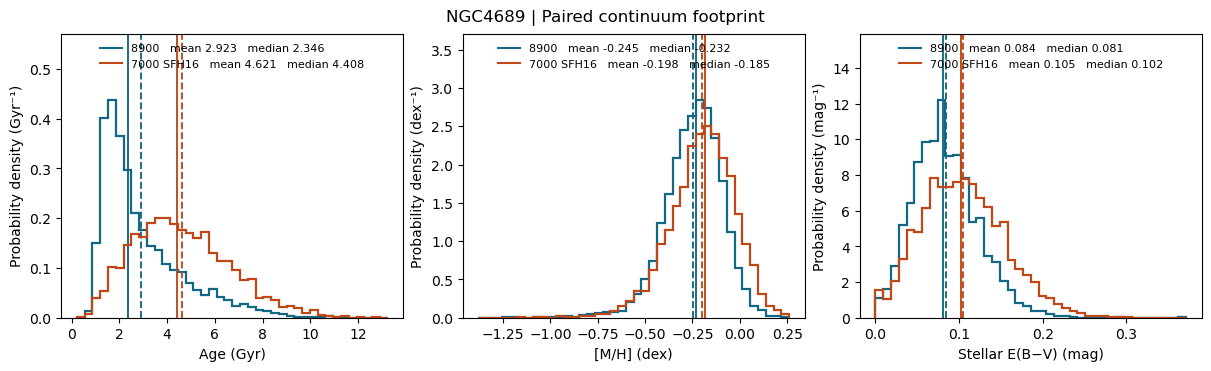

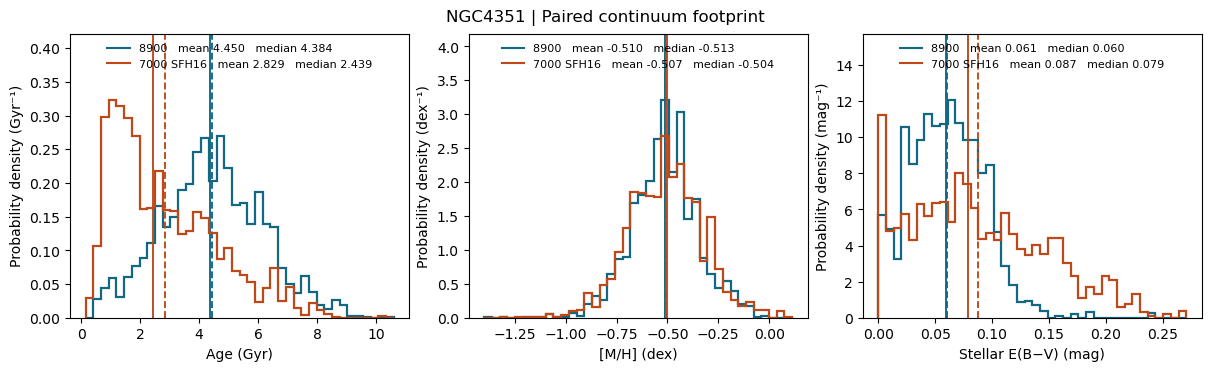

,Galaxy,Quantity,Unit,Run,Paired spaxels,Mean,Median,P16,P84,P84−P16
0,NGC4689,Age,Gyr,8900,352045,2.9229,2.3462,1.4722,4.5959,3.1237
1,NGC4689,Age,Gyr,7000 SFH16,352045,4.6212,4.4077,2.5686,6.6781,4.1096
2,NGC4689,[M/H],dex,8900,352045,-0.2445,-0.2323,-0.3825,-0.1034,0.2791
3,NGC4689,[M/H],dex,7000 SFH16,352045,-0.1983,-0.1849,-0.3612,-0.0330,0.3281
4,NGC4689,Stellar E(B−V),mag,8900,352045,0.0841,0.0809,0.0464,0.1224,0.0760
5,NGC4689,Stellar E(B−V),mag,7000 SFH16,352045,0.1049,0.1020,0.0551,0.1540,0.0989
6,NGC4351,Age,Gyr,8900,76341,4.4496,4.3838,2.6541,6.1667,3.5126
7,NGC4351,Age,Gyr,7000 SFH16,76341,2.8288,2.4391,1.0576,4.6807,3.6231
8,NGC4351,[M/H],dex,8900,76341,-0.5102,-0.5130,-0.6562,-0.3614,0.2948
9,NGC4351,[M/H],dex,7000 SFH16,76341,-0.5073,-0.5041,-0.6816,-0.3297,0.3519


In [6]:
distribution_fields = {
    "AGE": ("Age", "Gyr"),
    "METAL": ("[M/H]", "dex"),
    "EBV": ("Stellar E(B−V)", "mag"),
}
distribution_colors = dict(zip(RUNS, ("#126782", "#BF4818")))
distribution_rows = []
for galaxy in GALAXIES:
    fig, axes = plt.subplots(1, 3, figsize=(12, 3.6), layout="constrained")
    for ax, (key, (label, unit)) in zip(axes, distribution_fields.items()):
        maps = [cases[galaxy, run][key] for run in RUNS]
        paired = results[galaxy]["use"] & np.isfinite(maps[0]) & np.isfinite(maps[1])
        if not paired.any():
            raise ValueError(f"{galaxy}: no paired finite pixels for {key}")
        values = [image[paired] for image in maps]
        edges = np.histogram_bin_edges(np.concatenate(values), bins=40)
        for run, sample in zip(RUNS, values):
            p16, median, p84 = np.percentile(sample, [16, 50, 84])
            mean = sample.mean()
            color = distribution_colors[run]
            ax.hist(sample, bins=edges, density=True, histtype="step",
                    linewidth=1.6, color=color)
            ax.axvline(median, color=color, linewidth=1.35)
            ax.axvline(mean, color=color, linestyle="--", linewidth=1.35)
            ax.plot([], [], color=color, label=f"{run}   mean {mean:.3f}   median {median:.3f}")
            distribution_rows.append({
                "Galaxy": galaxy, "Quantity": label, "Unit": unit, "Run": run,
                "Paired spaxels": sample.size, "Mean": mean, "Median": median,
                "P16": p16, "P84": p84, "P84−P16": p84 - p16,
            })
        ax.set(xlabel=f"{label} ({unit})", ylabel=f"Probability density ({unit}⁻¹)")
        ax.legend(fontsize=8, frameon=False, loc="upper center")
        # Reserve room for the numeric labels above the distributions.
        ax.set_ylim(0, ax.get_ylim()[1] * 1.24)
    fig.suptitle(f"{galaxy} | Paired continuum footprint")
    plt.show()
    plt.close(fig)

distribution_summary = pd.DataFrame(distribution_rows)
display(distribution_summary.style.format({
    column: "{:.4f}" for column in ("Mean", "Median", "P16", "P84", "P84−P16")
}))

## Recalculate the age maps with MEANLOGAGE

The update announced in the [nGIST version comparison](https://chatgpt.com/c/6afa58cb-ac00-83ec-81c2-afd3cb9e4b4d) sets `MEAN_AGE_DEF: MEANLOGAGE` as the default. We apply that definition to the existing LIGHT-mode fits in four steps.

1. **Read the fitted weights and SSP ages.** In each run's `*_sfh_weights.fits`, each row of `WEIGHTS` is one Voronoi bin. Its elements are in the same order as the rows of `GRID`. For SSP $j$, the grid stores $\ell_j=\log_{10}(t_j/\mathrm{Gyr})$ in `GRID.LOGAGE`.
2. **Normalize within each bin and average the log ages.** For fitted coefficient $w_j$, use $f_j=w_j/\sum_k w_k$. The new map value is $A_{\mathrm{log}}=\sum_j f_j\ell_j$. For the plots, convert it to the geometric mean age $t_{\mathrm{geo}}=10^{A_{\mathrm{log}}}\,\mathrm{Gyr}$. The original definition instead averages the linear SSP ages, $t_{\mathrm{arith}}=\sum_j f_j10^{\ell_j}\,\mathrm{Gyr}$. For example, weights of 0.2 at 0.1 Gyr and 0.8 at 10 Gyr give an arithmetic mean of 8.02 Gyr, a mean log age of 0.60, and a geometric mean of 3.98 Gyr.
3. **Map the values back to the sky.** Assign each bin's value to its spaxels using that run's own `BINID`. Apply the same paired mask as in cell 10, with finite `SNR_POSTFIT > 25` in both runs. Reconstruct the old arithmetic age and compare it with the saved `AGE` on those pixels to check SSP ordering and spatial bin assignment.
4. **Repeat the age distribution comparison.** The panels show both definitions in Gyr on identical histogram edges. The tables also report the native mean-log values, with mean, median, P16, P84 and P84−P16. The paired shifts are calculated per spaxel as 7000 SFH16 minus 8900 before taking percentiles. Each selected spaxel contributes once.

The saved template coefficients supply both age summaries. This calculation uses the saved fit products and keeps the derived maps in memory.

In [7]:
age_map_fields = {
    "Arithmetic age": "Gyr",
    "Geometric age": "Gyr",
    "Mean log age (MEANLOGAGE)": "log₁₀(Gyr)",
}
age_maps = {}
age_checks, age_summary_rows, age_shift_rows = [], [], []
for galaxy in GALAXIES:
    use = results[galaxy]["use"]
    for run in RUNS:
        c = cases[galaxy, run]
        weights, log_age = c["weights"], c["log_age"]
        weight_sum = weights.sum(axis=1)
        arithmetic = (weights @ (10**log_age)) / weight_sum
        mean_log_age = (weights @ log_age) / weight_sum
        geometric = 10**mean_log_age
        reconstructed = map_values(c["binid"], arithmetic)
        np.testing.assert_allclose(reconstructed[use], c["AGE"][use], atol=2e-6, rtol=2e-7)
        if np.any(geometric > arithmetic * (1 + 1e-12)):
            raise ValueError(f"{galaxy} {run}: geometric age exceeds arithmetic age")
        age_checks.append({"Galaxy": galaxy, "Run": run, "Paired spaxels": use.sum(),
                           "Max |arithmetic − saved AGE| (Gyr)": np.max(np.abs(reconstructed[use] - c["AGE"][use]))})
        age_maps[galaxy, run] = {
            "Arithmetic age": np.where(use, reconstructed, np.nan),
            "Geometric age": np.where(use, map_values(c["binid"], geometric), np.nan),
            "Mean log age (MEANLOGAGE)": np.where(use, map_values(c["binid"], mean_log_age), np.nan),
        }
        for label, unit in age_map_fields.items():
            values = age_maps[galaxy, run][label][use]
            p16, median, p84 = np.percentile(values, [16, 50, 84])
            age_summary_rows.append({"Galaxy": galaxy, "Run": run, "Age definition": label, "Unit": unit,
                                     "Mean": values.mean(), "Median": median, "P16": p16, "P84": p84,
                                     "P84−P16": p84 - p16})
    for label, unit in age_map_fields.items():
        old, new = [age_maps[galaxy, run][label][use] for run in RUNS]
        delta = new - old
        p16, median, p84 = np.percentile(delta, [16, 50, 84])
        age_shift_rows.append({"Galaxy": galaxy, "Age definition": label, "Unit": unit,
                               "Paired spaxels": use.sum(), "Mean": delta.mean(),
                               "Median": median, "P16": p16, "P84": p84, "P84−P16": p84 - p16})

age_validation = pd.DataFrame(age_checks)
age_distributions = pd.DataFrame(age_summary_rows)
paired_age_shifts = pd.DataFrame(age_shift_rows)
display(age_validation)
display(age_distributions.round(4))
display(paired_age_shifts.round(4))

,Galaxy,Run,Paired spaxels,Max |arithmetic − saved AGE| (Gyr)
0,NGC4689,8900,352045,1.776357e-15
1,NGC4689,7000 SFH16,352045,3.552714e-15
2,NGC4351,8900,76341,1.776357e-15
3,NGC4351,7000 SFH16,76341,1.776357e-15


,Galaxy,Run,Age definition,Unit,Mean,Median,P16,P84,P84−P16
0,NGC4689,8900,Arithmetic age,Gyr,2.9229,2.3462,1.4722,4.5959,3.1237
1,NGC4689,8900,Geometric age,Gyr,1.6403,1.4317,0.8595,2.3905,1.5309
2,NGC4689,8900,Mean log age (MEANLOGAGE),log₁₀(Gyr),0.1566,0.1559,-0.0657,0.3785,0.4442
3,NGC4689,7000 SFH16,Arithmetic age,Gyr,4.6212,4.4077,2.5686,6.6781,4.1096
4,NGC4689,7000 SFH16,Geometric age,Gyr,2.0368,1.8049,0.9582,3.0612,2.1031
5,NGC4689,7000 SFH16,Mean log age (MEANLOGAGE),log₁₀(Gyr),0.2361,0.2564,-0.0186,0.4859,0.5045
6,NGC4351,8900,Arithmetic age,Gyr,4.4496,4.3838,2.6541,6.1667,3.5126
7,NGC4351,8900,Geometric age,Gyr,1.2134,1.0616,0.5553,1.8614,1.3060
8,NGC4351,8900,Mean log age (MEANLOGAGE),log₁₀(Gyr),0.0098,0.0260,-0.2554,0.2698,0.5253
9,NGC4351,7000 SFH16,Arithmetic age,Gyr,2.8288,2.4391,1.0576,4.6807,3.6231


,Galaxy,Age definition,Unit,Paired spaxels,Mean,Median,P16,P84,P84−P16
0,NGC4689,Arithmetic age,Gyr,352045,1.6983,1.6244,-0.0996,3.6316,3.7312
1,NGC4689,Geometric age,Gyr,352045,0.3965,0.2897,-0.4646,1.2672,1.7318
2,NGC4689,Mean log age (MEANLOGAGE),log₁₀(Gyr),352045,0.0794,0.0850,-0.1433,0.3018,0.4450
3,NGC4351,Arithmetic age,Gyr,76341,-1.6208,-1.7131,-3.7203,0.6078,4.3281
4,NGC4351,Geometric age,Gyr,76341,-0.1308,-0.1254,-0.8021,0.4806,1.2827
5,NGC4351,Mean log age (MEANLOGAGE),log₁₀(Gyr),76341,-0.0675,-0.0618,-0.3384,0.2153,0.5536


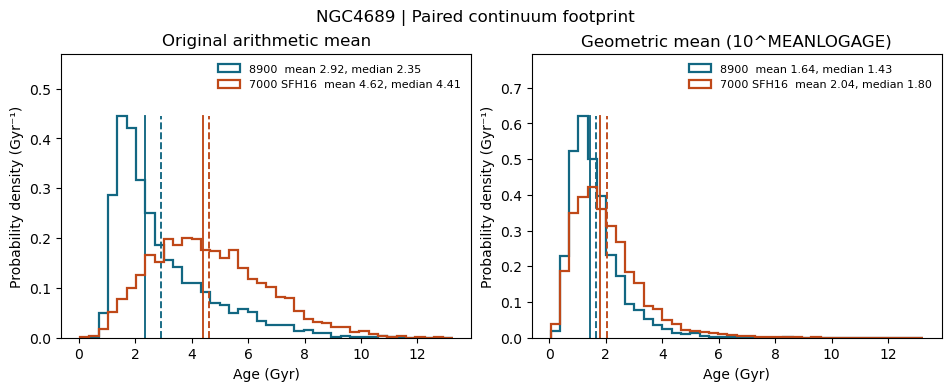

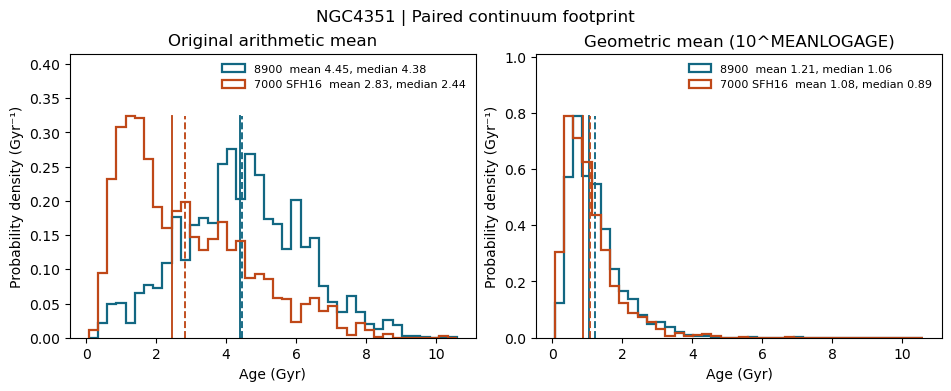

In [8]:
for galaxy in GALAXIES:
    use = results[galaxy]["use"]
    fig, axes = plt.subplots(1, 2, figsize=(9.4, 3.8), layout="constrained", sharex=True)
    labels = ("Arithmetic age", "Geometric age")
    bounds = np.concatenate([age_maps[galaxy, run][label][use] for run in RUNS for label in labels])
    edges = np.histogram_bin_edges(bounds, bins=40)
    for ax, label in zip(axes, labels):
        for run in RUNS:
            sample = age_maps[galaxy, run][label][use]
            color = distribution_colors[run]
            mean, median = sample.mean(), np.median(sample)
            ax.hist(sample, bins=edges, density=True, histtype="step", color=color, linewidth=1.6,
                    label=f"{run}  mean {mean:.2f}, median {median:.2f}")
            ax.axvline(mean, color=color, linestyle="--", linewidth=1.35, ymax=0.78)
            ax.axvline(median, color=color, linewidth=1.35, ymax=0.78)
        subtitle = "Original arithmetic mean" if label == "Arithmetic age" else "Geometric mean (10^MEANLOGAGE)"
        ax.set(title=subtitle, xlabel="Age (Gyr)", ylabel="Probability density (Gyr⁻¹)")
        ax.legend(loc="upper right", fontsize=8, frameon=False)
        ax.set_ylim(0, ax.get_ylim()[1] * 1.22)
    fig.suptitle(f"{galaxy} | Paired continuum footprint")
    plt.show()
    plt.close(fig)

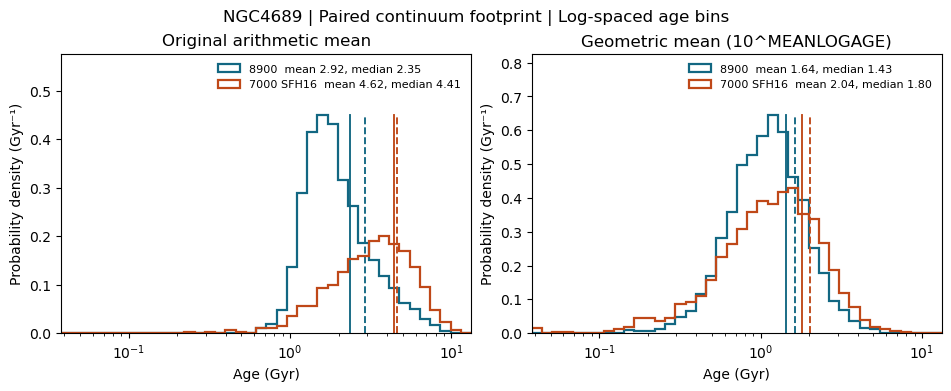

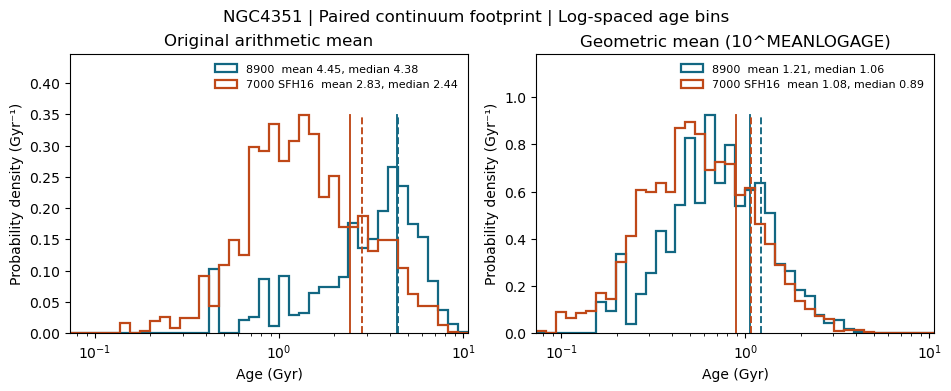

In [9]:
# Log-spaced age bins on a logarithmic Gyr axis. Density is per Gyr.
for galaxy in GALAXIES:
    use = results[galaxy]["use"]
    fig, axes = plt.subplots(1, 2, figsize=(9.4, 3.8), layout="constrained", sharex=True)
    labels = ("Arithmetic age", "Geometric age")
    bounds = np.concatenate([age_maps[galaxy, run][label][use] for run in RUNS for label in labels])
    if not np.isfinite(bounds).all() or np.any(bounds <= 0):
        raise ValueError(f"{galaxy}: the log age axis requires positive finite ages")
    edges = np.geomspace(bounds.min(), bounds.max(), num=41)
    for ax, label in zip(axes, labels):
        for run in RUNS:
            sample = age_maps[galaxy, run][label][use]
            color = distribution_colors[run]
            mean, median = sample.mean(), np.median(sample)
            ax.hist(sample, bins=edges, density=True, histtype="step", color=color, linewidth=1.6,
                    label=f"{run}  mean {mean:.2f}, median {median:.2f}")
            ax.axvline(mean, color=color, linestyle="--", linewidth=1.35, ymax=0.78)
            ax.axvline(median, color=color, linewidth=1.35, ymax=0.78)
        subtitle = "Original arithmetic mean" if label == "Arithmetic age" else "Geometric mean (10^MEANLOGAGE)"
        ax.set(title=subtitle, xlabel="Age (Gyr)", ylabel="Probability density (Gyr⁻¹)")
        ax.set_xscale("log")
        ax.set_xlim(edges[0], edges[-1])
        ax.legend(loc="upper right", fontsize=8, frameon=False)
        ax.set_ylim(0, ax.get_ylim()[1] * 1.22)
    fig.suptitle(f"{galaxy} | Paired continuum footprint | Log-spaced age bins")
    plt.show()
    plt.close(fig)

## Paired-bin residual RMS on the common wavelength interval

Compare saved fit residuals on 4800–7000 Å using bins with identical spatial membership in the two runs and the strict SNR_POSTFIT > 25 cut in both runs. If a galaxy has no exact matches, report that and retain the result for the other galaxy. The comparison gives each matched bin pair one vote. It uses the intersection of the saved run-wide `GOODPIX` indices, a common wavelength grid, and the available prepared observations and best fits. `GOODPIX` is the global mask stored by nGIST. The final per-bin clipping mask is unavailable in these products.

The RMS is calculated here from the saved spectra. In each run directory, the observed spectrum is the `SPEC` dataset in `<run_id>_bin_spectra.hdf5`. The model spectrum is the `BESTFIT` column of the `BESTFIT` HDU in `<run_id>_sfh_bestfit.fits`. Both files provide `LOGLAM` for alignment. The best-fit FITS also supplies `GOODPIX`.

For each bin and run, on the shared channels, the notebook calculates

$$
\mathrm{RMS}_{\%}=100\frac{\sqrt{\langle(F_{\mathrm{obs}}-F_{\mathrm{fit}})^2\rangle}}{\operatorname{median}(F_{\mathrm{obs}})}.
$$

The table reports the median and P16–P84 across bin pairs. The paired change is first computed within each pair, as 7000 SFH16 minus 8900, then summarized in percentage points. nGIST's saved `RED_CHI2` is a different statistic. The observed spectra are also compared after this normalization to quantify input shape differences. This is an in-sample residual check for the saved runs. It incorporates differences in preprocessing, fixed kinematics, fit range, and polynomial degree. Both models have seen the wavelengths used in this check.

A controlled test would fit the same bin spectra and fixed kinematics at both wavelength limits, crossing the limits with both polynomial degrees. Use the same noise model and score the two fits on identical withheld blocks inside their common interval. If stitching is the concern, repeat this for spectra extracted from the same sky apertures in overlapping pointings. For a test involving the red-only interval, forward-model the short-fit SSP mixture there with a continuum prescription defined over the full range. Avoid extrapolating its fitted multiplicative polynomial. Use independent spectra, or mock recovery with plausible calibration and template mismatch, to assess the ages and M/L directly.

In [10]:
import h5py


def saved_fit_channels(case):
    path = Path(case["info"]["weights_path"])
    prefix = path.parent.name
    bestfit_path = product(path.parent, prefix + "_sfh_bestfit")
    with fits.open(bestfit_path, memmap=True) as h:
        loglam = h["LOGLAM"].data["LOGLAM"].copy()
        good = h["GOODPIX"].data["GOODPIX"].astype(int)
        if (good < 0).any() or (good >= loglam.size).any():
            raise ValueError(f"{bestfit_path}: invalid GOODPIX indices")
    return bestfit_path, loglam, good


def read_saved_fit(case, bestfit_path, loglam, ids, channels):
    path = bestfit_path.parent / (bestfit_path.parent.name + "_bin_spectra.hdf5")
    unique_ids, inverse = np.unique(ids, return_inverse=True)
    with h5py.File(path, "r") as h:
        data_loglam = h["LOGLAM"][:]
        wave = np.exp(data_loglam)
        selection = np.flatnonzero((wave > case["info"]["LMIN"]) & (wave < case["info"]["LMAX"]))
        np.testing.assert_allclose(data_loglam[selection], loglam, atol=1e-12, rtol=0)
        if h["SPEC"].shape[1] != len(case["logml"]):
            raise ValueError(f"{path}: observed spectra and weight rows differ")
        observed = h["SPEC"][:, unique_ids][selection[channels]].T[inverse]
    with fits.open(bestfit_path, memmap=True) as h:
        model = h["BESTFIT"].data["BESTFIT"]
        if model.shape != (len(case["logml"]), len(loglam)):
            raise ValueError(f"{bestfit_path}: unexpected model dimensions")
        model = model[unique_ids][:, channels][inverse]
    return observed, model


def residual_check(galaxy):
    result = results[galaxy]
    pairs = result["pairs"][result["jaccard"] == 1]
    if len(pairs) == 0:
        print(f"{galaxy}: no exactly matched apertures after the S/N cut")
        return []
    old, new = [cases[galaxy, run] for run in RUNS]
    file0, wave0, good0 = saved_fit_channels(old)
    file1, wave1, good1 = saved_fit_channels(new)
    overlap = (np.exp(wave1) >= 4800) & (np.exp(wave1) <= 7000)
    channels = np.intersect1d(np.intersect1d(good0, good1), np.flatnonzero(overlap))
    if not channels.size:
        raise ValueError(f"{galaxy}: no shared wavelength channels")
    np.testing.assert_allclose(wave0[channels], wave1[channels], atol=1e-12, rtol=0)
    samples = []
    for start in range(0, len(pairs), 128):
        i0, i1 = pairs[start:start + 128].T
        obs0, fit0 = read_saved_fit(old, file0, wave0, i0, channels)
        obs1, fit1 = read_saved_fit(new, file1, wave1, i1, channels)
        finite = np.isfinite(obs0) & np.isfinite(obs1) & np.isfinite(fit0) & np.isfinite(fit1)
        complete = finite.all(axis=1)
        obs0, fit0, obs1, fit1 = [a[complete] for a in (obs0, fit0, obs1, fit1)]
        norm0 = np.median(obs0, axis=1, keepdims=True)
        norm1 = np.median(obs1, axis=1, keepdims=True)
        valid = (norm0[:, 0] > 0) & (norm1[:, 0] > 0)
        e0 = (obs0[valid] - fit0[valid]) / norm0[valid]
        e1 = (obs1[valid] - fit1[valid]) / norm1[valid]
        obs_difference = obs1[valid] / norm1[valid] - obs0[valid] / norm0[valid]
        samples.append(100 * np.sqrt(np.mean(np.stack([e0, e1, obs_difference])**2, axis=2)).T)
    values = np.concatenate(samples)
    if not len(values):
        raise ValueError(f"{galaxy}: no exact aperture pairs with complete valid spectra")
    measures = (values[:, 0], values[:, 1], values[:, 1] - values[:, 0], values[:, 2])
    labels = ("8900 residual RMS (%)", "7000 SFH16 residual RMS (%)",
              "Paired residual RMS change (percentage points)", "Observed spectral shape difference RMS (%)")
    return [dict(galaxy=galaxy, quantity=label, exact_pairs=len(pairs), valid_pairs=len(values),
                 channels=len(channels), p16=p16, median=median, p84=p84)
            for label, v in zip(labels, measures)
            for p16, median, p84 in [np.percentile(v, [16, 50, 84])]]


spectral_check = pd.DataFrame([row for g in GALAXIES for row in residual_check(g)])
display(spectral_check.round(4))

,galaxy,quantity,exact_pairs,valid_pairs,channels,p16,median,p84
0,NGC4689,8900 residual RMS (%),855,855,2208,2.6071,2.8972,3.1325
1,NGC4689,7000 SFH16 residual RMS (%),855,855,2208,2.5198,2.8178,3.0548
2,NGC4689,Paired residual RMS change (percentage points),855,855,2208,-0.1010,-0.0804,-0.0628
3,NGC4689,Observed spectral shape difference RMS (%),855,855,2208,0.0000,0.0000,0.0000
4,NGC4351,8900 residual RMS (%),159,159,2206,2.5509,2.7137,2.8810
5,NGC4351,7000 SFH16 residual RMS (%),159,159,2206,2.5296,2.7000,2.8686
6,NGC4351,Paired residual RMS change (percentage points),159,159,2206,-0.0240,-0.0141,-0.0084
7,NGC4351,Observed spectral shape difference RMS (%),159,159,2206,0.0000,0.0000,0.0000


## Residual RMS over each fit's full wavelength range

The preceding section scores both fits over the **same 4800–7000 Å channels**. Here, score each fit over its own native window and split the 8900 fit into its native 4800–7000 Å and 7000–8900 Å contributions. The sample is still restricted to exact bin-aperture matches passing `SNR_POSTFIT > 25` in both runs. A pair must have finite data and models on every included channel in both windows.

In each run, subtract the saved best fit from its observed spectrum and divide by that bin's median observed flux on the **shared** 4800–7000 Å channels. Then take the RMS in each reported window. The shared normalization keeps the red residual on the same fractional-flux scale as the blue residual. The native-window scores use each fit's saved global `GOODPIX`; the per-bin clipping masks are unavailable. Channel counts refer to the native log-wavelength sampling. The wavelength profiles take the RMS across matched pairs at each native log-wavelength channel. Each point is placed at its actual rest-frame wavelength in Å. Masked channels remain blank and break the connecting line.

**How to compare the scores.** Full-window RMS describes how closely each model follows its own fitted spectrum. Wavelengths differ in noise, calibration, sky subtraction and template mismatch, so the two full-window scores cannot rank the fits on the same data. The common-window score above makes that in-sample comparison. Comparing the two halves of the 8900 fit shows where its residuals are larger or smaller. There is no saved 7000 model beyond its fit boundary to score in the red interval.

In [11]:
def native_window_residuals(galaxy):
    result = results[galaxy]
    pairs = result["pairs"][result["jaccard"] == 1]
    if not len(pairs):
        print(f"{galaxy}: no exactly matched apertures after the S/N cut")
        return [], []
    paired_cases = [cases[galaxy, run] for run in RUNS]
    fits_by_run = [saved_fit_channels(c) for c in paired_cases]
    native = []
    for c, (_, loglam, good) in zip(paired_cases, fits_by_run):
        wave = np.exp(loglam)
        native.append(np.unique(good[(wave[good] >= c["info"]["LMIN"])
                                     & (wave[good] <= c["info"]["LMAX"])]))
    shared = np.intersect1d(*native)
    if not len(shared):
        raise ValueError(f"{galaxy}: no shared GOODPIX channels")
    np.testing.assert_allclose(fits_by_run[0][1][shared], fits_by_run[1][1][shared],
                               atol=1e-12, rtol=0)
    anchor_columns = [np.searchsorted(indices, shared) for indices in native]
    wavelengths = [np.exp(fit[1][indices]) for fit, indices in zip(fits_by_run, native)]
    blue8900 = wavelengths[0] <= 7000
    red8900 = (wavelengths[0] > 7000) & (wavelengths[0] <= 8900)
    if not (blue8900.any() and red8900.any() and (blue8900 | red8900).all()):
        raise ValueError(f"{galaxy}: unexpected coverage in the 8900 window")

    by_run = [[], []]
    for start in range(0, len(pairs), 128):
        ids = pairs[start:start + 128].T
        spectra = [read_saved_fit(c, file, loglam, bin_ids, indices)
                   for c, (file, loglam, _), bin_ids, indices
                   in zip(paired_cases, fits_by_run, ids, native)]
        anchors = [np.median(obs[:, cols], axis=1) for (obs, _), cols in zip(spectra, anchor_columns)]
        valid = np.logical_and.reduce([
            np.isfinite(obs).all(axis=1) & np.isfinite(fit).all(axis=1) & (anchor > 0)
            for (obs, fit), anchor in zip(spectra, anchors)
        ])
        for pieces, (obs, fit), anchor in zip(by_run, spectra, anchors):
            pieces.append(100 * (obs[valid] - fit[valid]) / anchor[valid, None])
    r8900, r7000 = [np.concatenate(pieces, axis=0) for pieces in by_run]
    if not len(r8900):
        raise ValueError(f"{galaxy}: no exact pairs with complete native spectra")

    windows = [
        ("7000 SFH16", "4800–7000", r7000),
        ("8900", "4800–8900", r8900),
        ("8900", "4800–7000", r8900[:, blue8900]),
        ("8900", ">7000–8900", r8900[:, red8900]),
    ]
    rows = []
    for run, window, residual in windows:
        rms = np.sqrt(np.mean(residual**2, axis=1))
        p16, median, p84 = np.percentile(rms, [16, 50, 84])
        rows.append({"Galaxy": galaxy, "Run": run, "Window (Å)": window,
                     "Exact pairs": len(pairs), "Valid pairs": len(rms), "Channels": residual.shape[1],
                     "P16 RMS (%)": p16, "Median RMS (%)": median, "P84 RMS (%)": p84})
    full_wavelengths = [np.exp(fit[1]) for fit in fits_by_run]
    return rows, list(zip(RUNS, full_wavelengths, native, (r8900, r7000)))


native_results = {g: native_window_residuals(g) for g in GALAXIES}
native_rms = pd.DataFrame([row for rows, _ in native_results.values() for row in rows])
display(native_rms.round(4))

,Galaxy,Run,Window (Å),Exact pairs,Valid pairs,Channels,P16 RMS (%),Median RMS (%),P84 RMS (%)
0,NGC4689,7000 SFH16,4800–7000,855,855,2208,2.5198,2.8178,3.0548
1,NGC4689,8900,4800–8900,855,855,3031,2.6224,2.8891,3.1064
2,NGC4689,8900,4800–7000,855,855,2210,2.6068,2.8967,3.1314
3,NGC4689,8900,>7000–8900,855,855,821,2.6476,2.8466,3.0743
4,NGC4351,7000 SFH16,4800–7000,159,159,2206,2.5296,2.7000,2.8686
5,NGC4351,8900,4800–8900,159,159,3018,2.3919,2.5380,2.7322
6,NGC4351,8900,4800–7000,159,159,2207,2.5505,2.7135,2.8805
7,NGC4351,8900,>7000–8900,159,159,811,1.8502,2.0043,2.2313


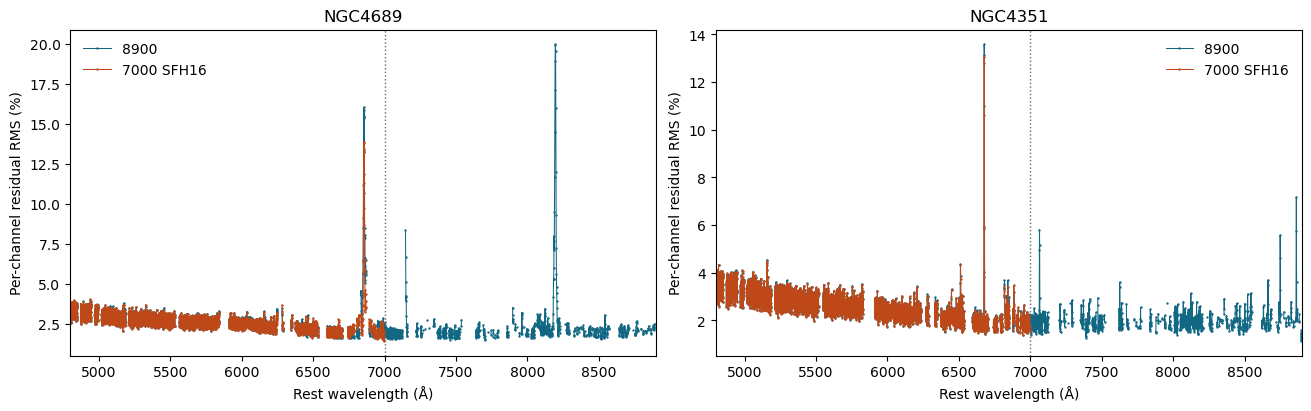

In [12]:
fig, axes = plt.subplots(1, len(GALAXIES), figsize=(13, 4), layout="constrained", squeeze=False)
for galaxy, ax in zip(GALAXIES, axes[0]):
    _, profiles = native_results[galaxy]
    for run, wave, goodpix, residual in profiles:
        channel_rms = np.full(wave.shape, np.nan)
        channel_rms[goodpix] = np.sqrt(np.mean(residual**2, axis=0))
        ax.plot(wave, channel_rms, color=distribution_colors[run], label=run,
                linewidth=0.75, marker=".", markersize=1.4)
    ax.axvline(7000, color="0.4", linestyle=":", linewidth=1)
    ax.set(title=galaxy, xlabel="Rest wavelength (Å)", ylabel="Per-channel residual RMS (%)",
           xlim=(4800, 8900))
    if profiles:
        ax.legend(frameon=False)
plt.show()
plt.close(fig)